<a href="https://colab.research.google.com/github/ZVSCR/UNIFESP_Numerical_Analysis/blob/main/tarefa_interpolacao_erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

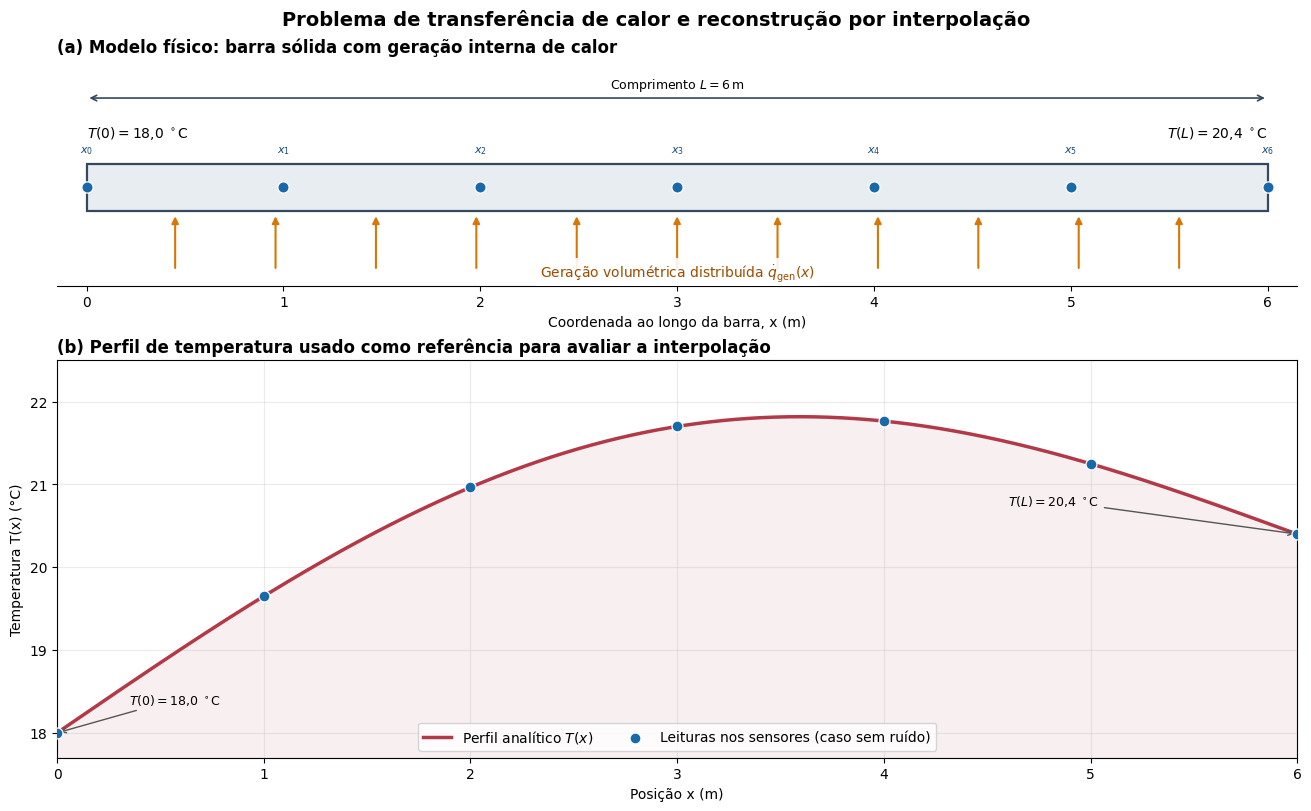

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# TODO: calcular a tabela de métricas na malha fina
# metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
# display(metricas_7)

# TODO: sobreponha os quatro métodos à função verdadeira e marque os nós

In [ ]:
# TODO: gráfico dos erros assinados método a método.
# Dica: erro = metodo(x_fino) - T_fino


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

# TODO: compare N = 5, 9, 13 e 17
# Para cada N, construa Lagrange com nós equiespaçados e com nós de Chebyshev.
# Calcule Emax e RMSE usando x_fino e T_fino.
# Organize os resultados em um DataFrame.

# tabela_nos = ...
# display(tabela_nos)

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

# Resultados
## Etapa 1

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


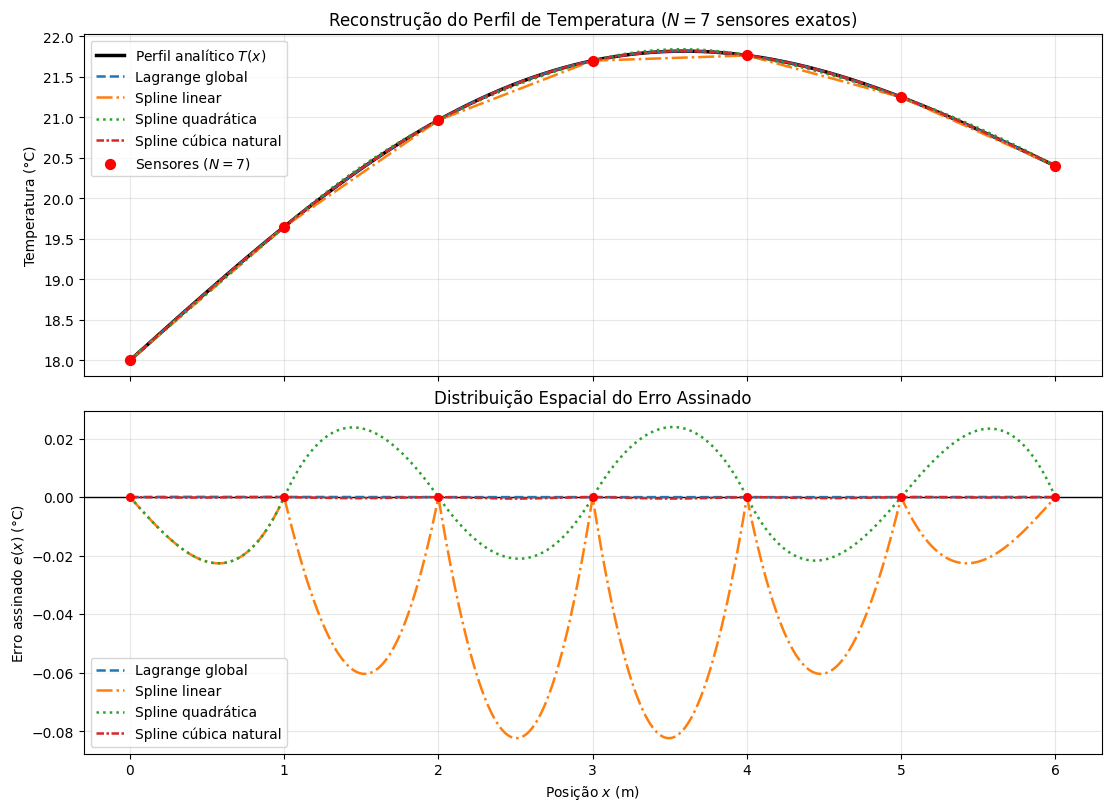

In [ ]:
# 1. Tabela de métricas na malha fina
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# 2. Gráfico comparativo das curvas e dos erros assinados
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)

# Painel superior: Temperatura reconstruída
ax1.plot(x_fino, T_fino, 'k-', lw=2.5, label='Perfil analítico $T(x)$')
estilos = ['--', '-.', ':', (0, (3, 1, 1, 1))]

for (nome, metodo), estilo in zip(metodos_7.items(), estilos):
    ax1.plot(x_fino, metodo(x_fino), linestyle=estilo, lw=1.8, label=nome)

ax1.scatter(x_nos_7, y_nos_7, color='red', zorder=5, s=50, label='Sensores ($N=7$)')
ax1.set_ylabel('Temperatura (°C)')
ax1.set_title('Reconstrução do Perfil de Temperatura ($N = 7$ sensores exatos)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Painel inferior: Erros assinados e(x) = T_interp(x) - T_ref(x)
ax2.axhline(0, color='black', lw=1, linestyle='-')
for (nome, metodo), estilo in zip(metodos_7.items(), estilos):
    erro = metodo(x_fino) - T_fino
    ax2.plot(x_fino, erro, linestyle=estilo, lw=1.8, label=nome)

ax2.scatter(x_nos_7, np.zeros_like(x_nos_7), color='red', zorder=5, s=30)
ax2.set_xlabel('Posição $x$ (m)')
ax2.set_ylabel('Erro assinado $e(x)$ (°C)')
ax2.set_title('Distribuição Espacial do Erro Assinado')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.show()

### Lagrange global e Spline cúbica natural
apresentam os menores erros (Emax e RMSE), pois o perfil T(x) é infinitamente diferenciável e suave. A spline cúbica natural apresenta um leve erro próximo às bordas (x = 0 e x = 6) porque impõe S''(0) = S''(6) = 0, o que coincide com o termo senoidal (sin(0) = sin(pi) = 0), tornando-a extremamente precisa para esta função específica.

### Spine quadrática
Sodre assimetria e propagação de oscilação devido à condição artificial c0 = 0 no primeiro subintervalo

### Spline linear
Apresenta o maior erro, subestimando a temperatura em todo o interior por conectar os pontos com segmentos retos em uma curva côncava

## Etapa 2

In [ ]:
valores_N = [5, 9, 13, 17]
resultados_etapa2 = []

for N in valores_N:
    # Nós equiespaçados
    x_eq = np.linspace(x_min, x_max, N)
    lag_eq = BarycentricInterpolator(x_eq, temperatura_real(x_eq))
    err_eq = lag_eq(x_fino) - T_fino

    # Nós de Chebyshev-Lobatto
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    lag_ch = BarycentricInterpolator(x_ch, temperatura_real(x_ch))
    err_ch = lag_ch(x_fino) - T_fino

    resultados_etapa2.append({
        "N": N,
        "E_max Equiespaçado (°C)": np.max(np.abs(err_eq)),
        "RMSE Equiespaçado (°C)": np.sqrt(np.mean(err_eq**2)),
        "E_max Chebyshev (°C)": np.max(np.abs(err_ch)),
        "RMSE Chebyshev (°C)": np.sqrt(np.mean(err_ch**2))
    })

tabela_nos = pd.DataFrame(resultados_etapa2)
display(tabela_nos)

,N,E_max Equiespaçado (°C),RMSE Equiespaçado (°C),E_max Chebyshev (°C),RMSE Chebyshev (°C)
0,5,4.530257e-03,2.159567e-03,2.326599e-03,1.532697e-03
1,9,1.043537e-06,3.438146e-07,2.167582e-07,1.202332e-07
2,13,5.908163e-11,1.545570e-11,3.630873e-12,1.932088e-12
3,17,1.989520e-12,2.445428e-13,1.065814e-14,3.758899e-15


* Como T(x) é uma função inteira (analítica em todo o plano complexo, composta apenas por uma reta e um seno), o erro de Lagrange decai exponencialmente rápido com o aumento de N para ambas as distribuições de nós, atingindo o limite da precisão de máquina (~ 10^-15 C) por volta de N = 13 ou N = 17

* Ainda assim, os nós exibem erro máximo consistemente menor para um mesmo N, pois minimizam a norma do polinômio nodal $\prod$ (x - x_i) e evitam o acúmulo de erro junto às extremidades (x=0 e x=6). Contudo, essa convergência rápido do polinômio equiespaçado não se generaliz para funções com singularidades próximas ao intervalo real (fenômeno de Runge)


## Etapa 3

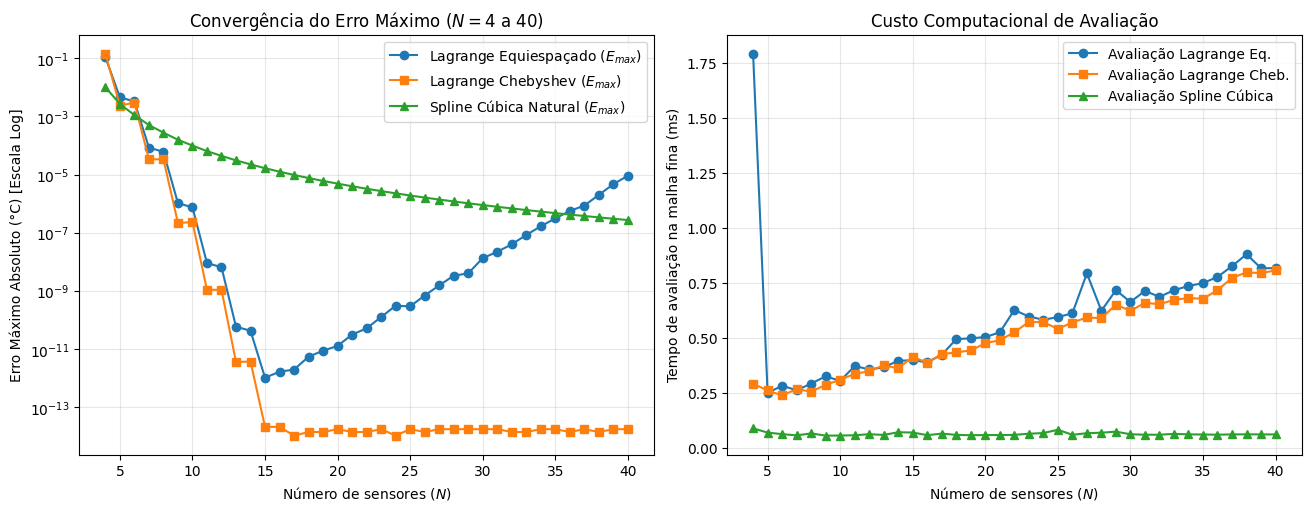

In [ ]:
import time

N_range = np.arange(4, 41)
historico = {
    "N": [],
    "Emax_eq": [], "RMSE_eq": [], "t_const_eq": [], "t_eval_eq": [],
    "Emax_ch": [], "RMSE_ch": [], "t_const_ch": [], "t_eval_ch": [],
    "Emax_sp": [], "RMSE_sp": [], "t_const_sp": [], "t_eval_sp": []
}

for N in N_range:
    historico["N"].append(N)

    # 1. Lagrange Equiespaçado
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    t0 = time.perf_counter()
    m_eq = BarycentricInterpolator(x_eq, y_eq)
    t1 = time.perf_counter()
    pred_eq = m_eq(x_fino)
    t2 = time.perf_counter()

    err_eq = pred_eq - T_fino
    historico["Emax_eq"].append(np.max(np.abs(err_eq)))
    historico["RMSE_eq"].append(np.sqrt(np.mean(err_eq**2)))
    historico["t_const_eq"].append(t1 - t0)
    historico["t_eval_eq"].append(t2 - t1)

    # 2. Lagrange Chebyshev
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)
    t0 = time.perf_counter()
    m_ch = BarycentricInterpolator(x_ch, y_ch)
    t1 = time.perf_counter()
    pred_ch = m_ch(x_fino)
    t2 = time.perf_counter()

    err_ch = pred_ch - T_fino
    historico["Emax_ch"].append(np.max(np.abs(err_ch)))
    historico["RMSE_ch"].append(np.sqrt(np.mean(err_ch**2)))
    historico["t_const_ch"].append(t1 - t0)
    historico["t_eval_ch"].append(t2 - t1)

    # 3. Spline Cúbica Natural
    t0 = time.perf_counter()
    m_sp = CubicSpline(x_eq, y_eq, bc_type="natural")
    t1 = time.perf_counter()
    pred_sp = m_sp(x_fino)
    t2 = time.perf_counter()

    err_sp = pred_sp - T_fino
    historico["Emax_sp"].append(np.max(np.abs(err_sp)))
    historico["RMSE_sp"].append(np.sqrt(np.mean(err_sp**2)))
    historico["t_const_sp"].append(t1 - t0)
    historico["t_eval_sp"].append(t2 - t1)

df_estudo = pd.DataFrame(historico)

# Gráficos de Erro (escala log) e Tempo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

ax1.semilogy(df_estudo["N"], df_estudo["Emax_eq"], 'o-', label='Lagrange Equiespaçado ($E_{max}$)')
ax1.semilogy(df_estudo["N"], df_estudo["Emax_ch"], 's-', label='Lagrange Chebyshev ($E_{max}$)')
ax1.semilogy(df_estudo["N"], df_estudo["Emax_sp"], '^-', label='Spline Cúbica Natural ($E_{max}$)')
ax1.set_xlabel('Número de sensores ($N$)')
ax1.set_ylabel('Erro Máximo Absoluto (°C) [Escala Log]')
ax1.set_title('Convergência do Erro Máximo ($N = 4$ a $40$)')
ax1.grid(True, which="both", alpha=0.3)
ax1.legend()

ax2.plot(df_estudo["N"], df_estudo["t_eval_eq"]*1000, 'o-', label='Avaliação Lagrange Eq.')
ax2.plot(df_estudo["N"], df_estudo["t_eval_ch"]*1000, 's-', label='Avaliação Lagrange Cheb.')
ax2.plot(df_estudo["N"], df_estudo["t_eval_sp"]*1000, '^-', label='Avaliação Spline Cúbica')
ax2.set_xlabel('Número de sensores ($N$)')
ax2.set_ylabel('Tempo de avaliação na malha fina (ms)')
ax2.set_title('Custo Computacional de Avaliação')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.show()

* Regime de $N$ pequeno a moderado ($4 \le N \le 15$): Os interpoladores globais de Lagrange (especialmente Chebyshev) superam a spline cúbica, atingindo o piso de arredondamento de ponto flutuante ($\approx 10^{-15}\text{ °C}$) com cerca de $14$ nós, enquanto a spline cúbica decai mais lentamente (taxa algébrica $O(h^4)$).

* Regime de $N$ grande ($N > 25$): Para Lagrange equiespaçado, erros de arredondamento em ponto flutuante começam a ser amplificados pela constante de Lebesgue (que cresce exponencialmente como $\sim 2^N / (e N \ln N)$), fazendo o erro voltar a subir levemente acima do piso numérico. Já Chebyshev e a Spline Cúbica permanecem numericamente estáveis.

* Custo computacional: A avaliação de Lagrange baricêntrico escala como $O(N \cdot M)$ (onde $M$ é o tamanho da malha de avaliação), tornando-se visivelmente mais lenta conforme $N$ cresce. A Spline Cúbica tem construção $O(N)$ (sistema tridiagonal) e avaliação $O(M \log N)$, sendo muito mais rápida e escalável para grandes malhas.

## Etapa 4

1. Escolha com poucos sensores exatos ($N \le 10$)

* Recomendação: Polinômio Global de Lagrange (preferencialmente com nós de Chebyshev-Lobatto) ou Spline Cúbica Natural.   

* Justificativa: Como a condução térmica estacionária com fonte distribuída gera perfis de temperatura espacialmente suaves, poucos pontos bem distribuídos capturam a curvatura global sem oscilações espúrias. Com $N=7$, ambos atingem $\text{RMSE}$ e erro máximo ($E_{max}$) muito inferiores aos das splines linear e quadrática. Se os sensores puderem ser posicionados livremente, os nós de Chebyshev minimizam o $E_{max}$.   

2. Mudança de estratégia ao aumentar o número de sensores ($N$ elevado)

* Recomendação: Migrar obrigatoriamente para a Spline Cúbica.   
* Justificativa: Com muitos sensores exatos, o polinômio global de Lagrange de alto grau sofre com o aumento da constante de Lebesgue (especialmente em malhas equiespaçadas), amplificando pequenos erros de arredondamento e aumentando o custo computacional de avaliação. A spline cúbica mantém suporte local (cada trecho depende fortemente apenas dos nós vizinhos), garantindo estabilidade numérica, baixo custo e convergência previsível de quarta ordem ($O(h^4)$) em $\text{RMSE}$ e $E_{max}$.   

3. Procedimento quando os sensores apresentam ruído de medição
* Recomendação: Abandonar a interpolação exata (tanto Lagrange de grau alto quanto splines interpolantes) e adotar aproximação/suavização, como Smoothing Splines (splines de suavização), regressão polinomial de baixo grau (ex.: grau 2 ou 3 via mínimos quadrados) ou filtragem prévia.

* Justificativa: Por definição, todo interpolador passa exatamente pelos pontos medidos ($p(x_i) = y_i + \varepsilon_i$). Quando há ruído $\varepsilon_i$, um polinômio de Lagrange de grau alto oscila violentamente entre os sensores para tentar acomodar as flutuações aleatórias, degradando severamente o $E_{max}$ e o $\text{RMSE}$ nos pontos internos. Métodos de ajuste por mínimos quadrados ou suavização filtram a variância do ruído e preservam a tendência física da condução de calor.  


4. Cuidados próximos às extremidades ($x = 0$ e $x = L$)

* Posicionamento e Contorno: Sempre que possível, instalar sensores diretamente nas extremidades ($x_0 = 0$ e $x_{N-1} = L$) ou utilizar condições de contorno físicas conhecidas (temperaturas prescritas ou fluxos de calor). No caso das splines cúbicas, se as derivadas nas bordas forem conhecidas fisicamente (lei de Fourier), usar a condição clamped (derivada primeira fixada) em vez da natural ($S''=0$), evitando distorções nos primeiros e últimos subintervalos. Se usar polinômios globais, concentrar sensores perto das bordas (distribuição tipo Chebyshev) reduz o $E_{max}$ de fronteira.


* Interpolação vs. Extrapolação: Estimativas dentro do intervalo $[x_{min}, x_{max}]$ coberto pelos sensores caracterizam interpolação, onde o erro é limitado pela distância entre nós e pela suavidade da curva. Tentar estimar a temperatura fora do trecho instrumentado ($x < x_{min}$ ou $x > x_{max}$) constitui extrapolação, operação altamente instável em que tanto polinômios globais quanto splines divergem rapidamente, elevando o $E_{max}$ sem controle físico.


5. Limitações quando a temperatura verdadeira é desconhecida em campo

* Ausência de métricas reais: Sem o perfil analítico de referência $T(x)$, não é possível calcular diretamente o $E_{max}$ ou o $\text{RMSE}$ verdadeiros da reconstrução.   

* Alternativas de validação: A equipe deve recorrer à validação cruzada (leave-one-out: remover um sensor por vez, interpolar com os demais e medir o $\text{RMSE}$ e $E_{max}$ na posição omitida), comparar modelos de complexidades diferentes para verificar consistência e propagar a incerteza instrumental dos sensores (via simulação de Monte Carlo) para estimar bandas de confiança nas regiões não medidas.
